[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vzavala/PCML_PEQ_2026/blob/main/JupyterNotebooks/PCML_Module1_NN_NODE_CSTR.ipynb)

# Module 1 Tutorial: Neural Networks and Neural ODEs for a CSTR
## Physics-Constrained Machine Learning: Concepts, Tools, and Algorithms

**Victor M. Zavala and Angan Mukherjee — University of Wisconsin-Madison**

In this tutorial, we will:

1. Define a nonlinear continuous stirred tank reactor (CSTR) model that we use to generate synthetic data.
2. Train a feedforward neural network (NN) that predicts the **steady-state** reactor outputs from the coolant temperature.
3. Train a neural ordinary differential equation (NODE) that predicts the **dynamic** response of the reactor.
4. Evaluate both models inside (interpolation) and outside (extrapolation) the range of the training data.

The NN and the NODE do not receive any information about the reactor model; they only see the data.

### Connection to the slides (Module 1)

- **Feedforward NN (Part A):** the NN is a parametric model $\hat y=\mathrm{ML}_\theta(x)$ built by forward propagation through layers.
  Training means solving $\min_\theta L(\theta)$ with a first-order method (Adam); PyTorch computes $\nabla_\theta L(\theta)$
  by back propagation (`loss.backward()`).
- **Neural ODE (Part B):** the NN models the right-hand side of the ODEs, $dx/dt=\mathrm{ML}_\theta(x,u)$. Training means
  repeatedly simulating the NODE and fitting the simulated trajectories to the measured trajectories.

### Before the workshop

Run these commands in a terminal:

    conda create -n pcml -c conda-forge python=3.11 numpy scipy matplotlib jupyterlab ipykernel
    conda activate pcml
    python -m pip install torch
    jupyter lab

On Google Colab, all required packages are already installed.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import torch
from torch import nn

SEED = 26
rng = np.random.default_rng(SEED)

torch.manual_seed(SEED)
torch.set_default_dtype(torch.float64)

plt.rcParams.update({
    "text.usetex": False, # Set to True if you have an external LaTeX installation
    "font.family": "serif",
    "axes.labelsize": 14,
    "axes.titlesize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 11,
})

### 1. Define the CSTR

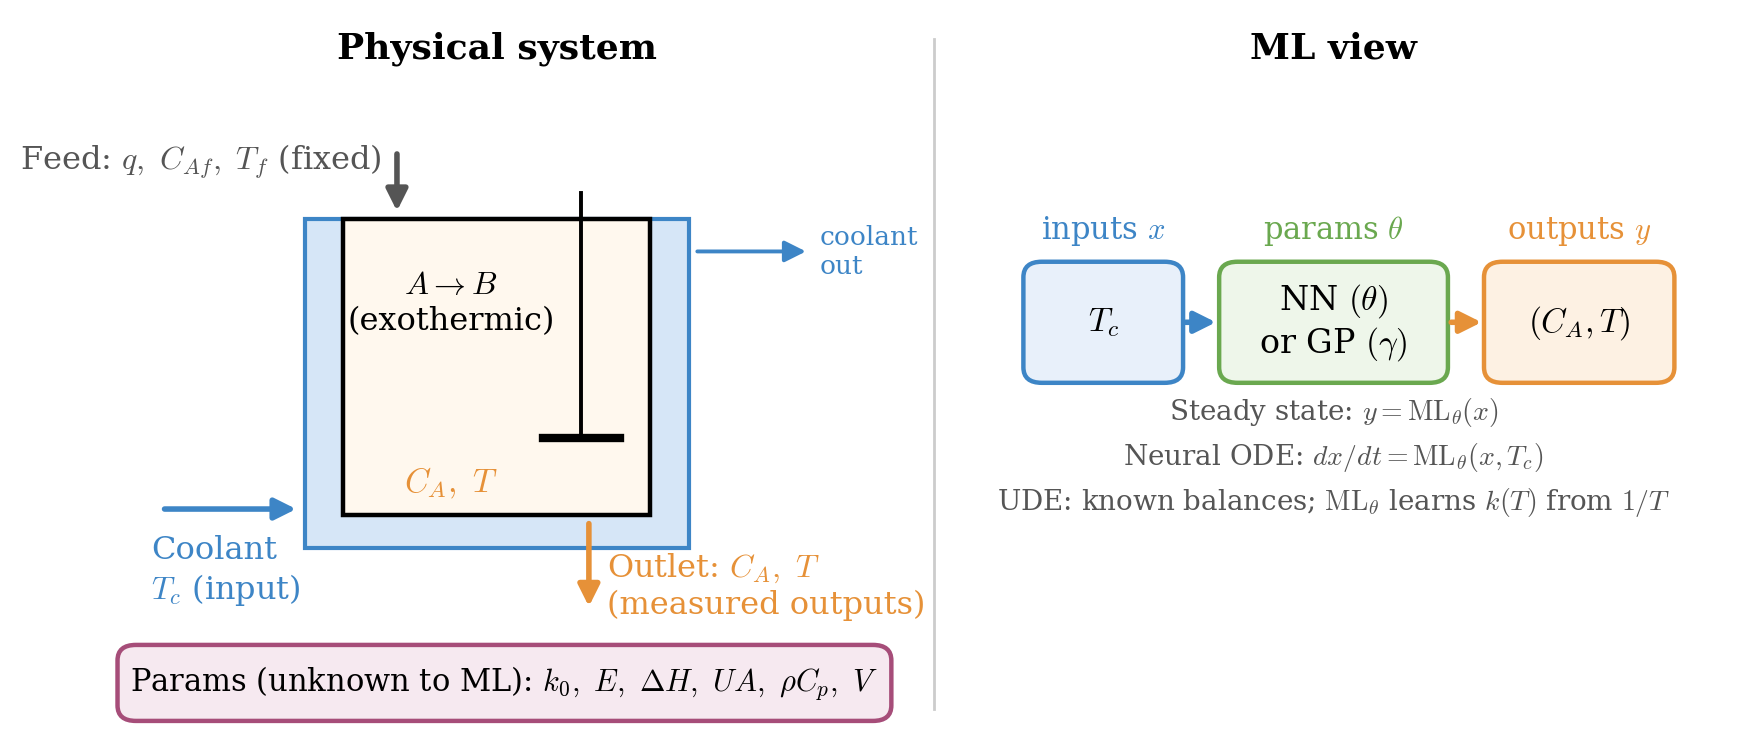

An exothermic, irreversible reaction $A\rightarrow B$ takes place in a cooled CSTR.
The states are the concentration of $A$, $C_A$ (mol/L), and the reactor temperature, $T$ (K).
The input is the coolant temperature, $T_c$ (K).

The mass and energy balances are

$$\frac{dC_A}{dt}=\frac{q}{V}(C_{Af}-C_A)-k_0e^{-E/RT}C_A$$

$$\frac{dT}{dt}=\frac{q}{V}(T_f-T)+\frac{(-\Delta H)}{\rho C_p}k_0e^{-E/RT}C_A+\frac{UA}{V\rho C_p}(T_c-T)$$

with parameters

| $q$ | $V$ | $C_{Af}$ | $T_f$ | $\rho$ | $C_p$ | $\Delta H$ | $E/R$ | $k_0$ | $UA$ |
|---|---|---|---|---|---|---|---|---|---|
| 100 L/min | 100 L | 1 mol/L | 350 K | 1000 g/L | 0.239 J/(g K) | $-5\times10^4$ J/mol | 8750 K | $7.2\times10^{10}$ 1/min | $5\times10^4$ J/(min K) |

The reaction rate depends exponentially on temperature; this makes the reactor response highly nonlinear.
For $T_c$ above about 304 K the reactor "ignites" and multiple steady states appear; we stay below this
region so that each $T_c$ gives a unique steady state.

**We use this model only to generate data.**

In [2]:
q, V = 100.0, 100.0          # L/min, L
CAf, Tf = 1.0, 350.0         # mol/L, K
rho, Cp = 1000.0, 0.239      # g/L, J/(g K)
dH = -5.0e4                  # J/mol
ER, k0 = 8750.0, 7.2e10      # K, 1/min
UA = 5.0e4                   # J/(min K)


def cstr_rhs(t, x, Tc):
    CA, T = x
    r = k0*np.exp(-ER/T)*CA
    dCA = q/V*(CAf - CA) - r
    dT = q/V*(Tf - T) - dH/(rho*Cp)*r + UA/(V*rho*Cp)*(Tc - T)
    return [dCA, dT]


def simulate(Tc, x0, t_eval):
    sol = solve_ivp(cstr_rhs, [0, t_eval[-1]], x0, args=(Tc,),
                    t_eval=t_eval, method="LSODA", rtol=1e-8, atol=1e-10)
    return sol.y.T


def steady_state(Tc):
    # integrate long enough to reach steady state
    return simulate(Tc, [0.9, 310.0], np.array([0.0, 200.0]))[-1]


labels = [r"$C_A$ (mol/L)", r"$T$ (K)"]

## Part A: Steady-State Neural Network

### 2. Generate steady-state data

We run $N=15$ steady-state experiments at coolant temperatures $T_c\in[285,302]$ K and measure the outputs
$y=(C_A,T)$. Measurements are corrupted by Gaussian noise with standard deviations

$$\sigma=(0.005\ \mathrm{mol/L},\ 0.5\ \mathrm{K})$$

We also compute the noise-free steady states on a fine grid $T_c\in[280,303]$ K to evaluate the models.

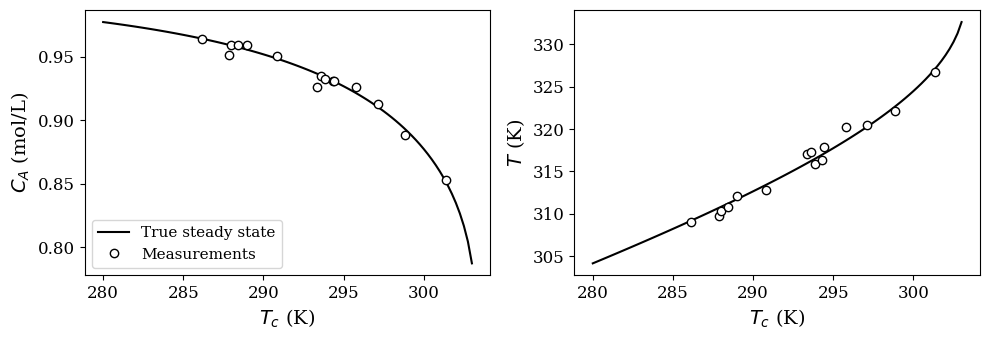

In [3]:
sigma = np.array([0.005, 0.5])

Tc_lo, Tc_hi = 285.0, 302.0
Tc_train = np.sort(rng.uniform(Tc_lo, Tc_hi, 15))
Tc_grid = np.linspace(280.0, 303.0, 93)

y_true = np.array([steady_state(Tc) for Tc in Tc_train])
y_obs = y_true + rng.normal(size=y_true.shape)*sigma
y_grid = np.array([steady_state(Tc) for Tc in Tc_grid])

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for j, ax in enumerate(axes):
    ax.plot(Tc_grid, y_grid[:, j], "k-", label="True steady state")
    ax.plot(Tc_train, y_obs[:, j], "o", mfc="w", mec="k", label="Measurements")
    ax.set(xlabel=r"$T_c$ (K)", ylabel=labels[j])
axes[0].legend()
plt.tight_layout()
plt.show()

### 3. Define the neural network

We use a feedforward NN with one input ($T_c$), one hidden layer with 10 tanh neurons, and two outputs ($C_A,T$):

$$h=\tanh(W_1x+b_1),\qquad \hat y=W_2h+b_2=\mathrm{ML}_\theta(x)$$

The number of parameters is $p=10+10+20+2=42$.

**Scaling.** Inputs and outputs have very different magnitudes. We scale them so that they are of order one:

$$x=\frac{T_c-293.5}{8.5},\qquad \tilde y=\frac{y-\bar y}{s_y}$$

where $\bar y$ and $s_y$ are the mean and standard deviation of the training outputs.
Without scaling, the temperature errors would dominate the loss and training would be slow.

### Training problem

Training consists of solving the optimization problem

$$\min_\theta\; L(\theta)=\frac{1}{2}\sum_{\omega\in\mathcal{S}}\|\tilde y_\omega-\mathrm{ML}_\theta(x_\omega)\|^2+\kappa\,\rho(\theta),\qquad \rho(\theta)=\|\theta\|^2$$

where $\omega\in\mathcal{S}$ are the $S=15$ experiments. (The code averages the squared errors over the $S$ experiments,
which only rescales $\kappa$.)

We use the **Adam** algorithm, a first-order method. PyTorch computes the gradient $\nabla_\theta L(\theta)$
using automatic differentiation (back propagation).

In [4]:
def scale_Tc(Tc):
    return (np.asarray(Tc) - 293.5)/8.5


y_mean, y_std = y_obs.mean(axis=0), y_obs.std(axis=0)


class SteadyStateNN(nn.Module):
    def __init__(self, n_hidden=10):
        super().__init__()
        self.hidden = nn.Linear(1, n_hidden)
        self.output = nn.Linear(n_hidden, 2)

    def forward(self, x):
        h = torch.tanh(self.hidden(x))
        return self.output(h)


def predict_ss(net, Tc):
    # returns predictions in physical units
    x = torch.tensor(scale_Tc(Tc)[:, None])
    with torch.no_grad():
        y_scaled = net(x).numpy()
    return y_scaled*y_std + y_mean


net = SteadyStateNN()
n_params = sum(p.numel() for p in net.parameters())
print("Number of NN parameters:", n_params)

Number of NN parameters: 42


Training time: 1.0 s
Final loss: 1.14e-02


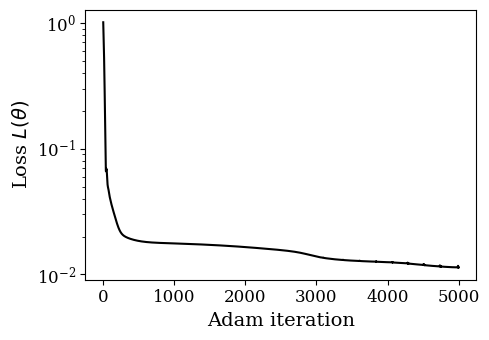

In [5]:
x_train = torch.tensor(scale_Tc(Tc_train)[:, None])
y_train = torch.tensor((y_obs - y_mean)/y_std)
kappa = 1e-5

optimizer = torch.optim.Adam(net.parameters(), lr=0.01)
history = []
t0 = time.perf_counter()

for epoch in range(5000):
    optimizer.zero_grad()
    data_loss = 0.5*torch.mean(torch.sum((net(x_train) - y_train)**2, dim=1))
    reg = sum(torch.sum(p**2) for p in net.parameters())
    loss = data_loss + kappa*reg
    loss.backward()           # back propagation: computes gradient of loss
    optimizer.step()          # Adam update of parameters
    history.append(loss.item())

print(f"Training time: {time.perf_counter() - t0:.1f} s")
print(f"Final loss: {history[-1]:.2e}")

plt.figure(figsize=(5, 3.5))
plt.semilogy(history, "k-")
plt.xlabel("Adam iteration")
plt.ylabel(r"Loss $L(\theta)$")
plt.tight_layout()
plt.show()

### 4. Evaluate the neural network

We compare NN predictions against the true steady states. The shaded region is the range covered by the training data.
Inside this range the NN **interpolates**; outside this range it **extrapolates**.

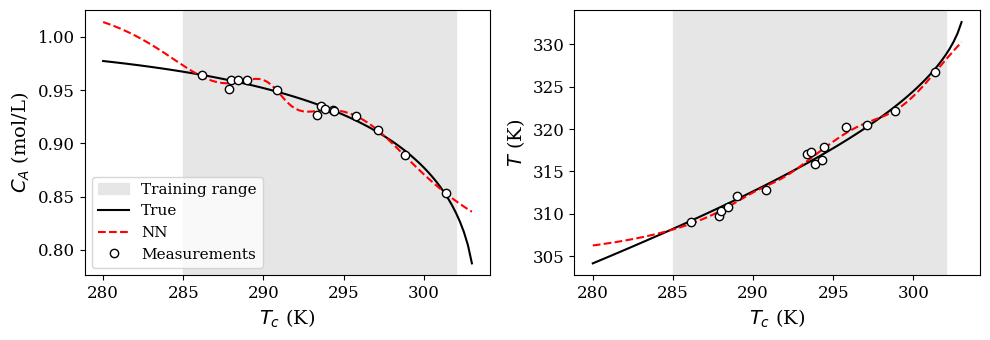

CA: RMSE inside range = 0.0052, outside range = 0.0270
T: RMSE inside range = 0.4506, outside range = 1.2389


In [6]:
y_nn = predict_ss(net, Tc_grid)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for j, ax in enumerate(axes):
    ax.axvspan(Tc_lo, Tc_hi, color="0.9", label="Training range")
    ax.plot(Tc_grid, y_grid[:, j], "k-", label="True")
    ax.plot(Tc_grid, y_nn[:, j], "r--", label="NN")
    ax.plot(Tc_train, y_obs[:, j], "o", mfc="w", mec="k", label="Measurements")
    ax.set(xlabel=r"$T_c$ (K)", ylabel=labels[j])
axes[0].legend()
plt.tight_layout()
plt.show()

inside = (Tc_grid >= Tc_lo) & (Tc_grid <= Tc_hi)
for j, name in enumerate(["CA", "T"]):
    rmse_in = np.sqrt(np.mean((y_nn[inside, j] - y_grid[inside, j])**2))
    rmse_out = np.sqrt(np.mean((y_nn[~inside, j] - y_grid[~inside, j])**2))
    print(f"{name}: RMSE inside range = {rmse_in:.4f}, outside range = {rmse_out:.4f}")

**Observations**

- The NN captures the nonlinear steady-state map well inside the training range (errors are comparable to the measurement noise).
- Outside the training range the NN is not reliable: it has no information about the steep rise in temperature as the reactor approaches ignition.
- The NN parameters have no physical meaning, and the NN does not tell us how uncertain its predictions are.

## Part B: Dynamic Neural ODE

### 5. Generate dynamic data

The reactor starts at the steady state for $T_c=290$ K. At $t=0$ we step the coolant temperature to a new value and
measure $C_A(t)$ and $T(t)$ every 0.5 min for 8 min (16 measurements per experiment).

- **Training experiments:** $T_c\in\{286, 294, 300\}$ K
- **Test experiments:** $T_c=297$ K (interpolation) and $T_c=303$ K (extrapolation)

We use the same measurement noise as before.

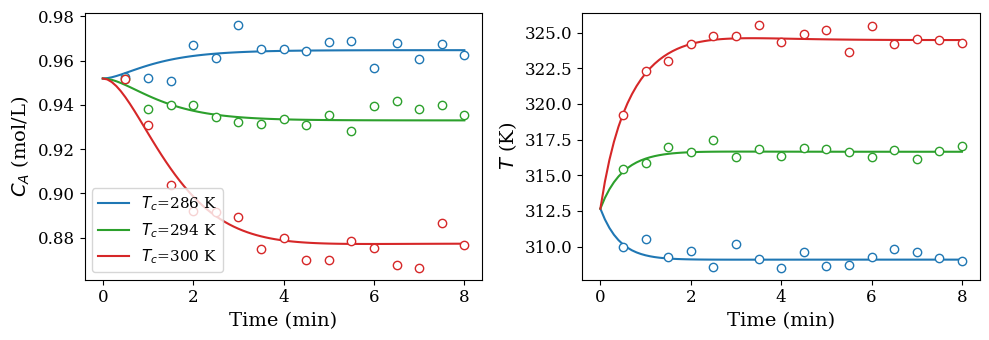

In [7]:
x0 = steady_state(290.0)
dt = 0.1
t_sim = np.arange(0.0, 8.0 + dt/2, dt)     # integration grid
obs_idx = np.arange(5, len(t_sim), 5)      # measurement every 0.5 min
t_obs = t_sim[obs_idx]

Tc_dyn_train = np.array([286.0, 294.0, 300.0])
Tc_dyn_test = np.array([297.0, 303.0])

X_true_train = np.array([simulate(Tc, x0, t_sim) for Tc in Tc_dyn_train])
X_true_test = np.array([simulate(Tc, x0, t_sim) for Tc in Tc_dyn_test])

Y_dyn = X_true_train[:, obs_idx, :] + rng.normal(size=(3, len(t_obs), 2))*sigma

colors = ["tab:blue", "tab:green", "tab:red"]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for k, Tc in enumerate(Tc_dyn_train):
    for j, ax in enumerate(axes):
        ax.plot(t_sim, X_true_train[k, :, j], "-", color=colors[k], label=fr"$T_c$={Tc:.0f} K")
        ax.plot(t_obs, Y_dyn[k, :, j], "o", mfc="w", mec=colors[k])
for j, ax in enumerate(axes):
    ax.set(xlabel="Time (min)", ylabel=labels[j])
axes[0].legend()
plt.tight_layout()
plt.show()

### 6. Define the neural ODE

A NODE uses a NN to model the **rate of change** of the states (the vector field):

$$\frac{d\hat x}{dt}=\mathrm{ML}_\theta(\hat x,T_c),\qquad \hat x(0)=x_0$$

Here, $\hat x=(\hat C_A,\hat T)$. The NN has three inputs (two states and $T_c$), one hidden layer with 16 tanh neurons, and
two outputs (the time derivatives); this gives $p=3\cdot16+16+16\cdot2+2=98$ parameters.
As before, we scale the NN inputs and outputs:

$$\frac{d\hat C_A}{dt}=0.05\,f_1,\qquad \frac{d\hat T}{dt}=10\,f_2,\qquad
(f_1,f_2)=\mathrm{ML}_\theta\!\left(\tfrac{\hat C_A-0.93}{0.05},\ \tfrac{\hat T-320}{10},\ \tfrac{T_c-293.5}{8.5}\right)$$

The scaling constants reflect the typical values and ranges of the states and of their rates of change.

**The NN predicts a derivative; simulating the NODE produces the trajectory.** We simulate the NODE with a
simple fixed-step Runge-Kutta (RK4) solver written in PyTorch; this allows PyTorch to compute gradients through the simulation.

### Training problem

The NODE is trained by fitting the simulated trajectories to the measured trajectories:

$$\min_\theta\; L(\theta)=\frac{1}{2}\sum_{\omega\in\mathcal{S}}\sum_{j=1}^{2}
\left(\frac{y_{\omega j}-\hat x_j(t_\omega;\theta)}{\sigma_j}\right)^2$$

where $\omega\in\mathcal{S}$ runs over the measurement times $t_\omega$ of all experiments (the code averages over all
measurements, which only rescales the loss).

Dividing by the noise level $\sigma_j$ puts concentration and temperature errors on the same scale.

Training requires **repeated simulations**: at each Adam iteration we simulate the NODE for all experiments,
compare the trajectories with the data, and update $\theta$.

In [8]:
class NeuralODE(nn.Module):
    def __init__(self, n_hidden=16):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(3, n_hidden), nn.Tanh(),
            nn.Linear(n_hidden, 2)
        )
        # start close to "no dynamics" for stable initial trajectories
        with torch.no_grad():
            self.net[2].weight.mul_(0.1)
            self.net[2].bias.zero_()

    def forward(self, x, Tc):
        # x has shape (batch, 2); Tc has shape (batch, 1)
        z = torch.cat([(x[:, :1] - 0.93)/0.05, (x[:, 1:] - 320.0)/10.0, (Tc - 293.5)/8.5], dim=1)
        f = self.net(z)
        return torch.cat([0.05*f[:, :1], 10.0*f[:, 1:]], dim=1)


def rk4(model, x0, Tc, n_steps, dt):
    # integrate the NODE; returns trajectory with shape (batch, n_steps+1, 2)
    x = x0
    path = [x]
    for _ in range(n_steps):
        a = model(x, Tc)
        b = model(x + dt*a/2, Tc)
        c = model(x + dt*b/2, Tc)
        d = model(x + dt*c, Tc)
        x = x + dt*(a + 2*b + 2*c + d)/6
        path.append(x)
    return torch.stack(path, dim=1)


node = NeuralODE()
print("Number of NODE parameters:", sum(p.numel() for p in node.parameters()))

Number of NODE parameters: 98


Iteration     0   loss = 1.613e+02


Iteration   300   loss = 1.775e+00


Iteration   600   loss = 9.909e-01


Iteration   900   loss = 9.314e-01


Iteration  1200   loss = 9.187e-01


Training time: 48.3 s


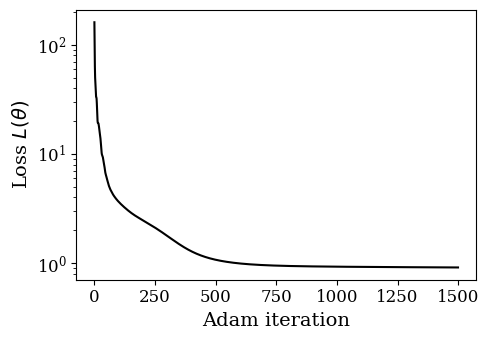

In [9]:
n_steps = len(t_sim) - 1
x0_batch = torch.tensor(np.tile(x0, (3, 1)))
Tc_batch = torch.tensor(Tc_dyn_train[:, None])
Y_batch = torch.tensor(Y_dyn)
sig = torch.tensor(sigma)

optimizer = torch.optim.Adam(node.parameters(), lr=0.01)
history_node = []
t0 = time.perf_counter()

for epoch in range(1500):
    optimizer.zero_grad()
    X_hat = rk4(node, x0_batch, Tc_batch, n_steps, dt)   # simulate NODE
    resid = (X_hat[:, obs_idx, :] - Y_batch)/sig
    loss = 0.5*torch.mean(torch.sum(resid**2, dim=2))
    loss.backward()          # gradient through the simulation
    optimizer.step()
    history_node.append(loss.item())
    if epoch % 300 == 0:
        print(f"Iteration {epoch:5d}   loss = {loss.item():.3e}")

print(f"Training time: {time.perf_counter() - t0:.1f} s")

plt.figure(figsize=(5, 3.5))
plt.semilogy(history_node, "k-")
plt.xlabel("Adam iteration")
plt.ylabel(r"Loss $L(\theta)$")
plt.tight_layout()
plt.show()

A loss close to 1 means that the trajectories match the data up to the measurement noise
(each scaled residual has unit variance).

### 7. Evaluate the neural ODE

We first compare the NODE trajectories against the training data, and then use the NODE to predict the response
to coolant temperatures that it has not seen.

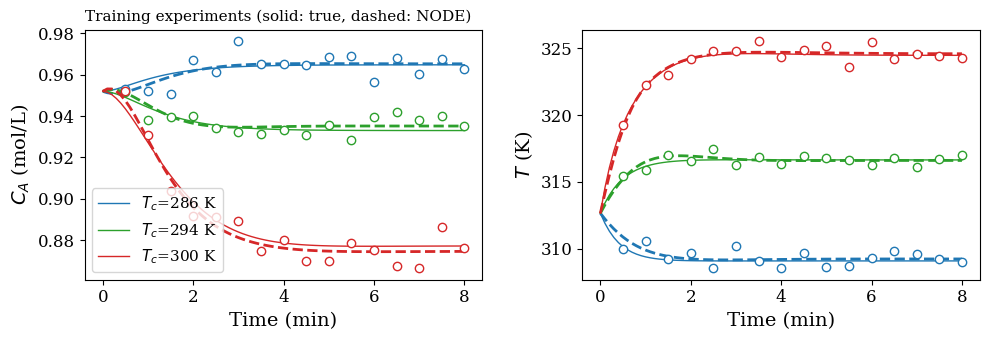

In [10]:
def predict_node(Tc_values):
    x0_b = torch.tensor(np.tile(x0, (len(Tc_values), 1)))
    Tc_b = torch.tensor(np.asarray(Tc_values)[:, None])
    with torch.no_grad():
        return rk4(node, x0_b, Tc_b, n_steps, dt).numpy()


X_node_train = predict_node(Tc_dyn_train)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for k, Tc in enumerate(Tc_dyn_train):
    for j, ax in enumerate(axes):
        ax.plot(t_sim, X_true_train[k, :, j], "-", color=colors[k], lw=1, label=fr"$T_c$={Tc:.0f} K")
        ax.plot(t_sim, X_node_train[k, :, j], "--", color=colors[k], lw=2)
        ax.plot(t_obs, Y_dyn[k, :, j], "o", mfc="w", mec=colors[k])
for j, ax in enumerate(axes):
    ax.set(xlabel="Time (min)", ylabel=labels[j])
axes[0].set_title("Training experiments (solid: true, dashed: NODE)", loc="left", fontsize=11)
axes[0].legend()
plt.tight_layout()
plt.show()

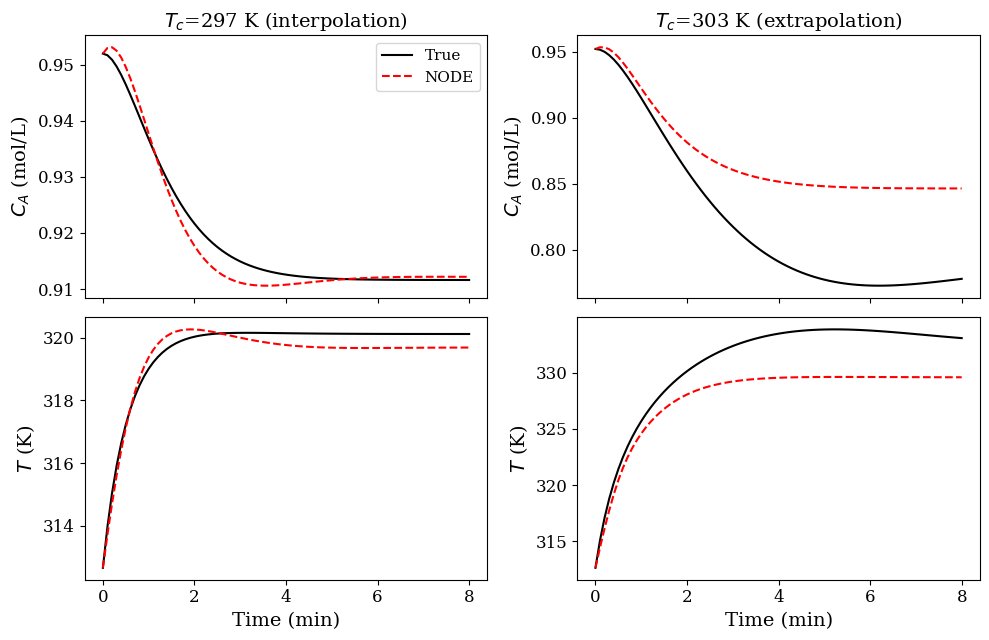

Tc = 297 K: RMSE CA = 0.0022 mol/L, RMSE T = 0.36 K
Tc = 303 K: RMSE CA = 0.0549 mol/L, RMSE T = 3.29 K


In [11]:
X_node_test = predict_node(Tc_dyn_test)

fig, axes = plt.subplots(2, 2, figsize=(10, 6.5), sharex=True)
for k, (Tc, title) in enumerate(zip(Tc_dyn_test, ["interpolation", "extrapolation"])):
    for j in range(2):
        ax = axes[j, k]
        ax.plot(t_sim, X_true_test[k, :, j], "k-", label="True")
        ax.plot(t_sim, X_node_test[k, :, j], "r--", label="NODE")
        ax.set(ylabel=labels[j])
    axes[0, k].set_title(fr"$T_c$={Tc:.0f} K ({title})")
for ax in axes[1]:
    ax.set(xlabel="Time (min)")
axes[0, 0].legend()
plt.tight_layout()
plt.show()

for k, Tc in enumerate(Tc_dyn_test):
    err = np.sqrt(np.mean((X_node_test[k] - X_true_test[k])**2, axis=0))
    print(f"Tc = {Tc:.0f} K: RMSE CA = {err[0]:.4f} mol/L, RMSE T = {err[1]:.2f} K")

**Observations**

- With only three experiments, the NODE learns a vector field that reproduces the training trajectories.
- The NODE also predicts the response to a new coolant temperature inside the training range reasonably well.
- For $T_c=303$ K, the reactor operates close to ignition and the dynamics are qualitatively different;
  the NODE has not seen this behavior and its predictions degrade.
- Training is more expensive than for the steady-state NN: every iteration requires simulating the NODE.

### 8. Key takeaways

- NNs are **flexible and powerful**: a small NN learned the nonlinear steady-state behavior of the CSTR from 15 experiments,
  and a NODE learned its dynamics from 3 experiments, without knowing the reactor model.
- NNs are **parametric**: training finds a single best set of parameters $\theta$ by optimization.
- NNs are reliable inside the range of the data, but they cannot know what they have not seen, and they do not tell us how
  uncertain their predictions are. The GP tutorial shows a conceptually different approach; Modules 2 and 3 show how physics
  and uncertainty quantification help.

### 9. Optional exercises

1. **Amount of data.** Reduce the number of steady-state experiments to 5. How do the NN predictions change?
2. **Network size.** Change the number of hidden neurons (e.g., 3 or 50). When does the NN start to overfit the noise?
3. **Learning rate.** Train the NN with learning rates of 0.001 and 0.1. How do the convergence and the final loss change?
4. **More experiments.** Add a fourth training experiment at $T_c=303$ K. Does the NODE extrapolate better?
5. **Physics.** The NODE does not know that $C_A\ge 0$ or that the inlet and outflow terms are linear in the states.
   How could we embed this knowledge into the model? (This is the topic of Module 2.)

### References

- Chen, R. T. Q., Rubanova, Y., Bettencourt, J., and Duvenaud, D. (2018). *Neural Ordinary Differential Equations*. NeurIPS. https://arxiv.org/abs/1806.07366
- Kingma, D. P., and Ba, J. (2015). *Adam: A Method for Stochastic Optimization*. ICLR. https://arxiv.org/abs/1412.6980
- Seborg, D. E., Edgar, T. F., Mellichamp, D. A., and Doyle, F. J. (2016). *Process Dynamics and Control*, 4th ed. Wiley (CSTR model).
- Zavala, V. M. (2025). *Statistics for Chemical Engineers*. Cambridge University Press.